# Choosing the Next Word: Greedy Decoding, Temperature, Top-k, Top-p

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/teaching-nlp-notebooks-sampling/blob/main/01_sampling_visual.ipynb)

After every prompt, GPT-2 small (OpenAI, 2019; 124 million parameters) has a probability for each of its 50,257 tokens. A token is a word or a piece of a word, usually with its leading space: ` surmounting` is split into ` sur`, `mount`, `ing`. A decoding rule is the recipe for picking one next token from these probabilities; applied 30 times in a row, it gives a continuation of 30 tokens. Four rules are in common use: greedy decoding, temperature, top-k and top-p.

Run the two setup cells first; on the first run, GPT-2 small (548 MB) is downloaded. In each section, write down an answer to the question, move the sliders, then open the answer. Charts and sentences are redrawn a few seconds after a slider is released, and after a new prompt in the text box when Enter is pressed. On Colab, a GPU runtime is faster.

In the sentences, the prompt is grey and each new token has a background colour set by GPT-2's own probability of that token at T = 1, before temperature, top-k or top-p: white for likely tokens, dark orange for tokens of probability 0.001 or less. Hover over a token to see its probability; ↵ is a line break.

In [1]:
# @title Setup: GPT-2 small and the decoding rules (run this cell first)
import functools, html, inspect, subprocess, sys, warnings

warnings.filterwarnings("ignore")
try:
    import transformers  # preinstalled in Colab
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers"], check=True)

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, display
from huggingface_hub.utils import logging as hub_logging
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
from transformers.utils import logging as hf_logging

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
torch.set_grad_enabled(False)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Loading GPT-2 small; on the first run, 548 MB are downloaded ...")
tok = GPT2TokenizerFast.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2").eval().to(DEVICE)
V = len(tok)  # 50,257 tokens

AUSTEN = "It is a truth universally acknowledged that"
PEAKED = "The Prime Minister of the United"
FLAT = "I went to the"
BANK = "The central bank decided to"
PROMPTS = [AUSTEN, PEAKED, FLAT, BANK]

BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c9c8c2", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 9, "legend.frameon": False,
})


def forward(seqs):
    """GPT-2's scores at every position of each token list in `seqs` (all of one length), float64 on the CPU."""
    return model(torch.tensor(seqs, device=DEVICE)).logits.double().cpu()


@functools.lru_cache(maxsize=128)
def logits(text):
    """GPT-2's score z_i for every token i that may follow `text`."""
    z = forward([tok(text).input_ids])[0, -1].numpy()
    z.setflags(write=False)
    return z


def softmax(z, T=1.0):
    """Probabilities from the scores z at temperature T. T = 0 puts all mass on the largest score."""
    if T == 0:
        p = np.zeros(len(z))
        p[np.argmax(z)] = 1.0
        return p
    e = np.exp((np.asarray(z) - np.max(z)) / T)
    return e / e.sum()


def top_k_filter(p, k):
    """Keep the k likeliest tokens (ties at the boundary kept), rescale them to sum to 1."""
    q = np.where(p >= np.sort(p)[-k], p, 0.0)
    return q / q.sum()


def top_p_filter(p, top_p):
    """Keep the smallest set of likeliest tokens whose probabilities add up to at least top_p."""
    order = np.argsort(p)                      # least likely first
    drop = np.cumsum(p[order]) <= 1 - top_p    # the tail holding at most 1 - top_p
    drop[-1] = False                           # the likeliest token always stays
    q = p.copy()
    q[order[drop]] = 0.0
    return q / q.sum()


def min_p_filter(p, p_base):
    """Keep every token whose probability is at least p_base times the largest probability."""
    q = np.where(p >= p_base * p.max(), p, 0.0)
    return q / q.sum()


def penalise(z, seen, theta):
    """Repetition penalty: scores of tokens already in the text, divided by theta if positive, times theta if negative."""
    z = np.array(z)
    s = z[seen]
    z[seen] = np.where(s < 0, s * theta, s / theta)
    return z


def next_token_dist(z, T=0.0, k=0, top_p=1.0, min_p=0.0):
    """The distribution the next token is drawn from: temperature, then top-k, top-p, min-p (k = 0: no top-k)."""
    p = softmax(z, T)
    if k:
        p = top_k_filter(p, k)
    if top_p < 1:
        p = top_p_filter(p, top_p)
    if min_p > 0:
        p = min_p_filter(p, min_p)
    return p


def generate(text, n_tokens=30, T=0.0, k=0, top_p=1.0, min_p=0.0, theta=1.0, n=1, draw=0):
    """n continuations of `text`, token by token. Each is (tokens, GPT-2's probability at T = 1 of each token)."""
    rng = np.random.default_rng(draw)
    start = tok(text).input_ids
    seqs = [list(start) for _ in range(n)]
    probs = [[] for _ in range(n)]
    for _ in range(n_tokens):
        Z = forward(seqs)[:, -1].numpy()
        for s in range(n):
            z = penalise(Z[s], np.unique(seqs[s]), theta) if theta != 1 else Z[s]
            t = int(rng.choice(V, p=next_token_dist(z, T, k, top_p, min_p)))
            probs[s].append(softmax(Z[s])[t])
            seqs[s].append(t)
    out = []
    for seq, pr in zip(seqs, probs):
        new = seq[len(start):]
        end = new.index(tok.eos_token_id) + 1 if tok.eos_token_id in new else len(new)  # stop at <|endoftext|>
        out.append((new[:end], pr[:end]))
    return out


def word(i):
    """Token i as text, without GPT-2's leading space."""
    s = tok.decode([int(i)])
    return s.strip() or repr(s)


def shade(p):
    """Background colour for a token of probability p: white near 1, dark orange at 0.001 and below."""
    level = np.clip(-np.log10(max(p, 1e-12)) / 3, 0, 1)
    r, g, b, _ = plt.get_cmap("Oranges")(0.8 * level)
    return f"rgb({r * 255:.0f},{g * 255:.0f},{b * 255:.0f})"


def show_text(text, tokens, probs, label=""):
    """The prompt in grey, then each new token on a background set by GPT-2's probability of it."""
    spans = "".join(
        f'<span title="probability {p:.3g}" style="background:{shade(p)};color:#0b0b0b">'
        f'{html.escape(tok.decode([t])).replace(chr(10), "↵")}</span>'
        for t, p in zip(tokens, probs))
    head = f'<b style="color:#52514e">{html.escape(label)}</b> ' if label else ""
    display(HTML(
        f'<div style="font-family:Menlo,monospace;font-size:12px;line-height:1.8;background:#fff;'
        f'color:#0b0b0b;padding:4px 8px;margin:2px 0;border-left:3px solid {GREY}">'
        f'{head}<span style="color:#8a8983">{html.escape(text)}</span>{spans}</div>'))


def colour_key():
    cells = "".join(f'<span style="background:{shade(p)};color:#0b0b0b;padding:0 6px">{p:g}</span> '
                    for p in (1, 0.1, 0.01, 0.001))
    display(HTML(f'<div style="font-size:11px;color:#52514e;background:#fff;padding:2px 6px">'
                 f'background: GPT-2\'s probability of each new token at T = 1, before any rule: {cells}</div>'))


def sentences(text, n=3, n_tokens=30, label="", **rule):
    """Print n continuations of `text` under one decoding rule."""
    for tokens, probs in generate(text, n_tokens, n=n, **rule):
        show_text(text, tokens, probs, label)


def bars(ax, p, keep=None, n=20, color=BLUE, order=None, label=None):
    """Bar chart of the n likeliest tokens; tokens outside `keep` in grey."""
    top = np.argsort(-p)[:n] if order is None else order
    colours = [color if keep is None or keep[i] else GREY for i in top]
    ax.bar(np.arange(len(top)), p[top], width=0.7, color=colours, label=label)
    ax.set_xticks(np.arange(len(top)), [word(i) for i in top], rotation=55, ha="right")
    ax.set_ylabel("probability")
    ax.set_xlabel("next token")
    return top


def slider(lo, hi, step, value, name=""):
    kind = widgets.IntSlider if isinstance(step, int) else widgets.FloatSlider
    return kind(min=lo, max=hi, step=step, value=value, description=name, continuous_update=False)


def prompt_box(value=AUSTEN):
    """A text box with the four prompts as suggestions; any other text works too (press Enter)."""
    return widgets.Combobox(value=value, options=PROMPTS, ensure_option=False, description="prompt",
                            continuous_update=False, layout=widgets.Layout(width="90%"))


def explore(f, **controls):
    """Sliders for the arguments of f; the output is redrawn when a slider is released."""
    missing = set(inspect.signature(f).parameters) - set(controls)
    assert not missing, f"no control for {missing}"
    @functools.wraps(f)
    def g(**kwargs):
        if "prompt" in kwargs:
            kwargs["prompt"] = kwargs["prompt"].strip() or AUSTEN  # an empty box falls back to the Austen prompt
        f(**kwargs)
    widgets.interact(g, **controls)


print(f"GPT-2 small loaded: {sum(x.numel() for x in model.parameters()):,} parameters, {V:,} tokens.")

Loading GPT-2 small; on the first run, 548 MB are downloaded ...


GPT-2 small loaded: 124,439,808 parameters, 50,257 tokens.


In [2]:
# @title Charts for the sections below (run this cell)
def count(n):
    return f"{n:,} token" + ("" if n == 1 else "s")


def show_distribution(prompt=AUSTEN):
    p = softmax(logits(prompt))
    fig, ax = plt.subplots(figsize=(8, 2.6))
    top = bars(ax, p, n=15)
    ax.set_title(f'GPT-2 small, after "{prompt}"')
    plt.show()
    print(f'likeliest next token: "{word(top[0])}", probability {p[top[0]]:.3f}')
    print(f"the 15 tokens in the chart have {np.sort(p)[::-1][:15].sum():.3f} of the probability together")
    print(f"tokens needed to reach 0.9 of the probability: {int((top_p_filter(p, 0.9) > 0).sum()):,} of {V:,}")


def show_greedy(prompt=AUSTEN, n_tokens=40):
    colour_key()
    sentences(prompt, n=1, n_tokens=n_tokens, T=0.0, label="greedy")


def temperature_bars(ax, z, temps, colours):
    top = np.argsort(-z)[:12]
    w = 0.8 / len(temps)
    for j, (T, c) in enumerate(zip(temps, colours)):
        x = np.arange(len(top)) + (j - (len(temps) - 1) / 2) * w
        ax.bar(x, softmax(z, T)[top], w, color=c, label=f"T = {T:g}")
    ax.set_xticks(np.arange(len(top)), [word(i) for i in top], rotation=55, ha="right")
    ax.set_ylabel("probability")
    ax.set_xlabel("next token")
    ax.legend()


def compare_temperatures(prompt, temps):
    z = logits(prompt)
    fig, ax = plt.subplots(figsize=(8, 2.6))
    temperature_bars(ax, z, temps, (BLUE, ORANGE, AQUA))
    ax.set_title(f'after "{prompt}": the 12 likeliest tokens at three temperatures')
    plt.show()
    colour_key()
    for T in temps:
        sentences(prompt, n=1, T=T, label=f"T = {T:g}")


def show_temperature(prompt=AUSTEN, T=0.0, draw=0):
    z = logits(prompt)
    fig, ax = plt.subplots(figsize=(8, 2.6))
    temperature_bars(ax, z, (1.0, T), (GREY, ORANGE))
    ax.set_title(f'after "{prompt}"')
    plt.show()
    p = softmax(z, T)
    print(f'probability of "{word(np.argmax(z))}": {softmax(z)[np.argmax(z)]:.3f} at T = 1, {p.max():.3f} at T = {T:g}')
    colour_key()
    sentences(prompt, n=3, T=T, draw=draw, label=f"T = {T:g}")


def show_cut(ax, p, q, title, n=20):
    bars(ax, p, keep=q > 0, n=n)
    ax.set_title(title)


def show_top_k(prompt=FLAT, k=5, T=1.0, draw=0):
    p = softmax(logits(prompt), T)
    q = top_k_filter(p, k)
    fig, ax = plt.subplots(figsize=(8, 2.6))
    show_cut(ax, p, q, f'top-k {k} after "{prompt}": kept tokens blue, cut tokens grey')
    plt.show()
    kept, mass, i = int((q > 0).sum()), p[q > 0].sum(), np.argmax(q)
    print(f"kept: {count(kept)} with {mass:.3f} of the probability; cut: {count(V - kept)}")
    print(f'after rescaling, "{word(i)}" has probability {p[i]:.3f} / {mass:.3f} = {q[i]:.3f}')
    colour_key()
    sentences(prompt, n=3, T=T, k=k, draw=draw, label=f"top-k {k}")


def show_top_p(prompt=FLAT, top_p=0.9, T=1.0, draw=0):
    p = softmax(logits(prompt), T)
    q = top_p_filter(p, top_p)
    kept = int((q > 0).sum())
    fig, ax = plt.subplots(figsize=(8, 2.6))
    show_cut(ax, p, q, f'top-p {top_p:g} after "{prompt}": {count(kept)} kept (blue), the rest cut (grey)', n=30)
    ax.set_yscale("log")
    ax.set_ylabel("probability (log scale)")
    plt.show()
    print(f"kept: {count(kept)} with {p[q > 0].sum():.3f} of the probability; cut: {count(V - kept)}")
    colour_key()
    sentences(prompt, n=3, T=T, top_p=top_p, draw=draw, label=f"top-p {top_p:g}")


def compare_rules(prompts, top_p=0.9, k=50):
    fig, axes = plt.subplots(1, len(prompts), figsize=(9, 3))
    for ax, prompt in zip(axes, prompts):
        p = softmax(logits(prompt))
        q = top_p_filter(p, top_p)
        show_cut(ax, p, q, f'"{prompt}"\ntop-p {top_p:g}: {count(int((q > 0).sum()))} kept (blue), the rest cut (grey)')
        ax.set_yscale("log")
        ax.set_ylabel("probability (log scale)")
    plt.tight_layout()
    plt.show()
    for prompt in prompts:
        p = softmax(logits(prompt))
        qp, qk = top_p_filter(p, top_p), top_k_filter(p, k)
        print(f'"{prompt}"\n   top-p {top_p:g}: {int((qp > 0).sum()):5,} tokens, probability {p[qp > 0].sum():.3f}'
              f'\n   top-k {k}:  {int((qk > 0).sum()):5,} tokens, probability {p[qk > 0].sum():.3f}')


def playground(prompt=BANK, T=0.0, k=0, top_p=1.0, n_tokens=30, draw=0):
    rule = "greedy" if T == 0 else f"T = {T:g}" + (f", top-k {k}" if k else "") + (f", top-p {top_p:g}" if top_p < 1 else "")
    kept = int((next_token_dist(logits(prompt), T, k, top_p) > 0).sum())
    print(f"{rule}: {count(kept)} can be drawn at the first step")
    colour_key()
    sentences(prompt, n=5, n_tokens=n_tokens, T=T, k=k, top_p=top_p, draw=draw, label=rule)

## 1. Next-Token Probabilities After a Prompt

After a prompt, GPT-2 gives every token a score, and the scores are turned into probabilities that are positive and add up to 1. Four prompts recur, under short names in the code:

- `AUSTEN`: `It is a truth universally acknowledged that`
- `PEAKED`: `The Prime Minister of the United` (one token has most of the probability)
- `FLAT`: `I went to the` (the probability is spread over thousands of tokens)
- `BANK`: `The central bank decided to`

Delete the text in the prompt box to see all four; pick one or type your own, then press Enter.

**Question.** In the first cell, the prompt is the Austen prompt. In the box of the second cell, type `The Prime Minister of the United`: is the probability of the likeliest token above or below 0.5? How many tokens are needed to reach 0.9 of the probability, and how many after `I went to the`?

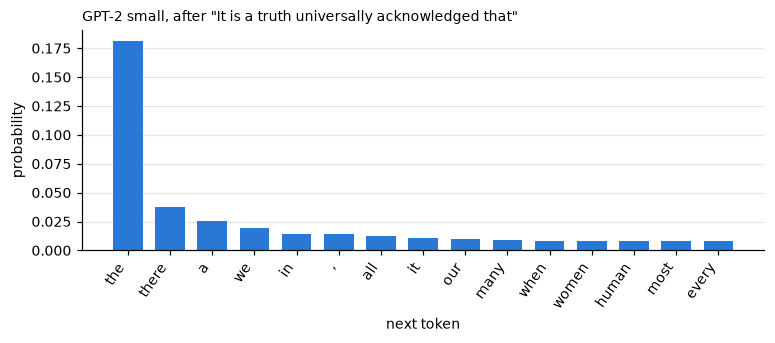

likeliest next token: "the", probability 0.182
the 15 tokens in the chart have 0.375 of the probability together
tokens needed to reach 0.9 of the probability: 3,784 of 50,257


In [3]:
show_distribution(AUSTEN)

In [4]:
explore(show_distribution, prompt=prompt_box(AUSTEN))

<details><summary><b>Answer</b></summary>

Above: `Kingdom` has probability 0.799, and 2 tokens (`Kingdom`, `States`) reach 0.9. After `I went to the`, the likeliest token, `hospital`, has 0.033, and 4,797 tokens are needed. After the Austen prompt, `the` has 0.182 and 3,784 tokens are needed.

</details>

## 2. Greedy Decoding

Under greedy decoding, the likeliest token is picked at every step; in the code, greedy decoding is written `T = 0`.

**Question.** In the first cell, one sentence is repeated in 40 greedy tokens after the Austen prompt. Before moving the sliders: after `I went to the`, with 60 tokens, does greedy decoding repeat itself as well, and which phrase?

In [5]:
show_greedy(AUSTEN, n_tokens=40)

In [6]:
explore(show_greedy, prompt=prompt_box(AUSTEN), n_tokens=slider(10, 60, 10, 40))

<details><summary><b>Answer</b></summary>

Yes: `I was going to be taken to the hospital` comes four times in 60 tokens, and 12 of the 60 tokens are distinct. In the Austen loop, the backgrounds get lighter with each repetition: GPT-2's probability of `United` after `The` is 0.06 the second time, 0.35 the third, 0.76 the fourth and 0.94 the fifth. Once a phrase is in the text, its repetition is likelier, and under greedy decoding it is picked again. Holtzman et al. (2020, *The Curious Case of Neural Text Degeneration*) measured such loops on GPT-2 Large.

</details>

## 3. Temperature

With temperature T, every score is divided by T before the scores are turned into probabilities. Scores 2, 1, 0 divided by T = 0.5 are 4, 2, 0: the gaps double, and the probability of the likeliest token grows. Divided by T = 2 they are 1, 0.5, 0: the gaps halve, and the probabilities of rare tokens grow. The probabilities still add up to 1, and the order of the tokens is the same at every T.

For T above 0, the next token is drawn at random: a token of probability 0.18 is picked in about 18 of 100 draws, so three lines at one T differ. The slider `draw` gives another set of random draws. T = 0 stands for greedy decoding, where nothing is drawn and every line is the same.

**Question.** In the first cell, one line each is drawn at T = 0.7, 1, 1.5. With the slider, after the Austen prompt: what is the probability of `the` at T = 0.5, and at T = 2? Is the text at T = 2 English?

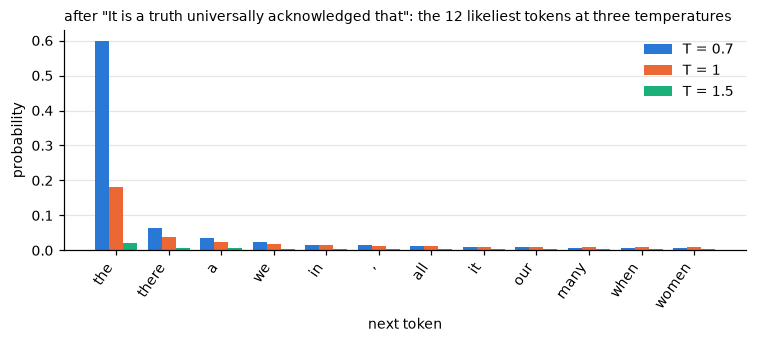

In [7]:
compare_temperatures(AUSTEN, temps=(0.7, 1.0, 1.5))  # T > 0: tokens are drawn at random; one line per temperature

In [8]:
explore(show_temperature, prompt=prompt_box(AUSTEN), T=slider(0.0, 2.0, 0.1, 0.0), draw=slider(0, 9, 1, 0))

<details><summary><b>Answer</b></summary>

0.885 at T = 0.5 and 0.005 at T = 2, against 0.182 at T = 1. At T = 2, the text is a list of unrelated words from the first token on, and 9 in 10 tokens have a probability below 0.001 (dark orange). In the three lines of the first cell, the tokens of probability below 0.01 number 8 at T = 0.7, 9 at T = 1 and 27 at T = 1.5; the tokens of probability 0.1 or more number 15, 12 and 2.

</details>

## 4. Top-k Sampling

Under top-k, the k likeliest tokens are kept, every other probability is set to zero, and each kept probability is divided by the kept total, so that the kept probabilities add up to 1 again. The next token is drawn from them at T = 1.

**Question.** The first cell is set to k = 5 after `I went to the`. With the slider: what share of the probability is kept at k = 5 after `The Prime Minister of the United`? What do the three lines at k = 1 have in common with section 2?

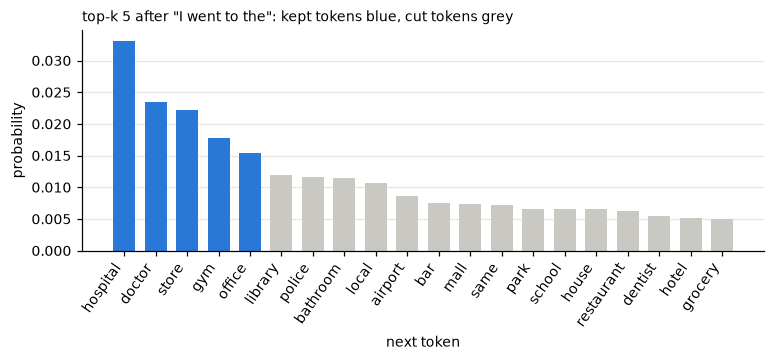

kept: 5 tokens with 0.112 of the probability; cut: 50,252 tokens
after rescaling, "hospital" has probability 0.033 / 0.112 = 0.295


In [9]:
show_top_k(FLAT, k=5, T=1.0)  # T > 0: tokens are drawn at random from the kept set

In [10]:
explore(show_top_k, prompt=prompt_box(FLAT), k=slider(1, 50, 1, 5),
        T=widgets.fixed(1.0),  # T > 0: tokens are drawn at random from the kept set
        draw=slider(0, 9, 1, 0))

<details><summary><b>Answer</b></summary>

0.992 after `The Prime Minister of the United`, against 0.112 after `I went to the`: with one value of k, 89 per cent of the probability is cut after one prompt and less than 1 per cent after the other. At k = 1, only the likeliest token is left, so every draw is greedy decoding: three identical lines, with the loop `I was going to be taken to the hospital` of section 2. With a small k, loops are frequent: at k = 5, the first line of the first cell repeats `I went to the hospital` three times.

</details>

## 5. Top-p Sampling, the Nucleus

Under top-p (Holtzman et al., 2020), the tokens are sorted from the likeliest down, and the shortest list whose probabilities add up to at least p is kept: the nucleus. The rest are cut, the kept ones rescaled, and the next token is drawn at T = 1. In the charts, the vertical axis is logarithmic, so that the small probabilities of the cut tokens are visible.

**Question.** In the first cell, the two prompts are compared at p = 0.9. With the slider, after `I went to the`: how many tokens are kept at p = 0.5, and at p = 0.99?

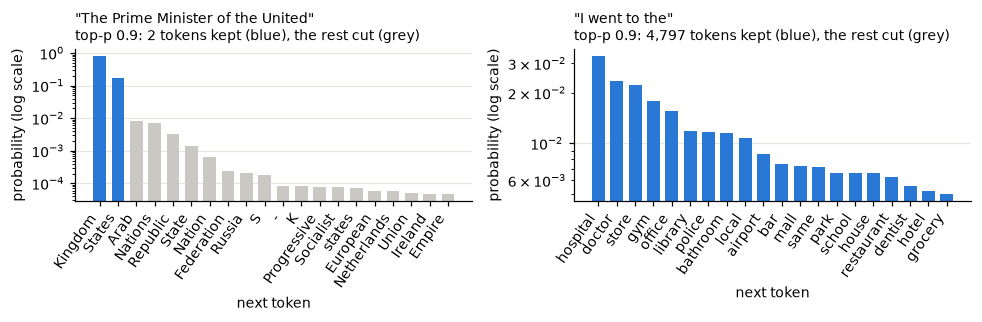

"The Prime Minister of the United"
   top-p 0.9:     2 tokens, probability 0.974
   top-k 50:     50 tokens, probability 0.996
"I went to the"
   top-p 0.9: 4,797 tokens, probability 0.900
   top-k 50:     50 tokens, probability 0.326


In [11]:
compare_rules([PEAKED, FLAT], top_p=0.9, k=50)

In [12]:
explore(show_top_p, prompt=prompt_box(FLAT), top_p=slider(0.05, 1.0, 0.05, 0.9),
        T=widgets.fixed(1.0),  # T > 0: tokens are drawn at random from the nucleus
        draw=slider(0, 9, 1, 0))

<details><summary><b>Answer</b></summary>

209 tokens at p = 0.5 and 17,247 at p = 0.99. At p = 0.9, the nucleus has 2 tokens after `The Prime Minister of the United` (`Kingdom`, `States`) and 4,797 after `I went to the`. Under top-k with k = 50, 50 tokens are kept in both cases: after the peaked prompt, 48 of them have a probability of 0.023 together; after the flat prompt, the 50 have 0.326. The size of the nucleus depends on the prompt: 2 tokens where GPT-2's probability is concentrated, thousands where it is spread.

</details>

## 6. Temperature, Top-k, Top-p Combined

In Hugging Face `transformers`, the settings are applied in the order temperature, top-k, top-p. Here, k = 0 or p = 1 means that the filter is off, and T = 0 means greedy decoding whatever k and p are. In `transformers`, greedy decoding is `do_sample=False`, and `temperature=0` gives an error.

**Task.** In the first cell, five continuations of `The central bank decided to` are drawn at T = 1.5, p = 1. With the sliders, lower p until the five continuations are English again: how many tokens can be drawn at the first step at your p? Then find a setting with T = 0.7 under which the five continuations are English and differ from each other.

In [13]:
playground(BANK, T=1.5)  # T > 0: five draws of one prompt show how sampled continuations differ

T = 1.5: 50,257 tokens can be drawn at the first step


In [14]:
explore(playground, prompt=prompt_box(BANK), T=slider(0.0, 2.0, 0.1, 0.0), k=slider(0, 100, 1, 0),
        top_p=slider(0.05, 1.0, 0.05, 1.0), n_tokens=slider(10, 60, 10, 30), draw=slider(0, 9, 1, 0))

<details><summary><b>Answer</b></summary>

At T = 1.5 and p = 1, all 50,257 tokens can be drawn at the first step, and after a few tokens each continuation is a list of unrelated words. At p = 0.5, 191 tokens are left at the first step, and the continuations are English again; at p = 0.9, 1,762 tokens. With T = 0.7 and p = 0.9, the five continuations are English and differ from each other; Holtzman et al. (2020) report their results at p = 0.95.

</details>

## Four Rules Compared

- **Greedy decoding** (T = 0): one continuation per prompt; after the Austen prompt, one sentence four times in 40 tokens.
- **Temperature**: the probability of `the` is 0.885 at T = 0.5, 0.182 at T = 1 and 0.005 at T = 2; the order of the tokens is the same at every T.
- **Top-k**: a fixed number of tokens, whatever their probability: at k = 5, 0.112 of the probability is kept after `I went to the` and 0.992 after `The Prime Minister of the United`.
- **Top-p**: a fixed share of the probability, whatever the number of tokens: at p = 0.9, 2 tokens are kept after `The Prime Minister of the United` and 4,797 after `I went to the`.